# PDFT Calculation for LiH

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Set up fragments and do reference calculation

In [2]:
# define geometry
sep = 3.014

mol = fgto.M(atom=f"""
    Li {-0.5*sep} 0 0
    H {0.5*sep} 0 0
""", unit='bohr', basis='cc-pvdz',
    fragments={0: [0], 1: [1]},  # atom indices (1-based) of each fragment  ;  use Mulliken population anaylisis for fract. charges
    ensembles={'charge': {0: {'charges': (0, -1),   'weights': (0.46358, 0.53642)},    # Li (w=0.46358), H- (w=0.53642) -> 3.53642 e
                          1: {'charges': (None, 0), 'weights': (0.53642, 0.46358)}}})  # no electrons (w=0.53642), H (w=0.46358)) -> 0.46358) e


my_dft = dft.RKS(mol.mol)        # or dft.UKS for open shells
my_dft.xc = 'PBE'
my_dft.grids.level = 6           # same grid level as f4b, to compare energies cleanly
my_dft.kernel()                  # ks.e_tot, ks.make_rdm1()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()
print(f"{Eref = :.8f}")

# Build an integration grid for the molecule.
grids = dft.gen_grid.Grids(mol.mol) # same for same basis with same number of atoms (ghost)
grids.level = 7
grids.build()
coords = grids.coords # [npoints, 3]
w = grids.weights # weights for integration
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0) # AO basis functions on the grid
nref = D2n(Dref, phi)

Eref = -8.04195083


---
## Do PDFT Calculations

### Inversion Method

In [3]:
mf1 = pdft.RKS(mol, method='inversion', maxiter=20)
mf1.kernel()
E_mf1, Df_mf1 = mf1.e_tot, mf1.make_rdm1()
nf_mf1 = D2n(Df_mf1[0]+Df_mf1[1], phi)

dE_mf1 = abs(Eref-E_mf1)
L1_mf1 = np.sum(np.abs(nf_mf1-nref)*w)
Nf_mf1 = np.sum(nf_mf1*w)
print(f"Energy difference (Ha): {dE_mf1:.3e}, Density error: {L1_mf1:.3e}")

P-DFT method=inversion xc=PBE fxc=PBE nao=19 grid=95288
  it    1  Ef =    -7.6983808518  dEf =         nan  |dVp| = 1.316e+00
  it    2  Ef =    -7.6564954084  dEf =   4.189e-02  |dVp| = 1.122e+00
  it    3  Ef =    -7.5990496913  dEf =   5.745e-02  |dVp| = 9.694e-01
  it    4  Ef =    -7.5494834996  dEf =   4.957e-02  |dVp| = 8.622e-01
  it    5  Ef =    -7.5104792435  dEf =   3.900e-02  |dVp| = 7.871e-01
  it    6  Ef =    -7.4810012827  dEf =   2.948e-02  |dVp| = 7.330e-01
  it    7  Ef =    -7.4590908659  dEf =   2.191e-02  |dVp| = 6.927e-01
  it    8  Ef =    -7.4429237249  dEf =   1.617e-02  |dVp| = 6.617e-01
  it    9  Ef =    -7.4310164251  dEf =   1.191e-02  |dVp| = 6.372e-01
  it   10  Ef =    -7.4222193531  dEf =   8.797e-03  |dVp| = 6.173e-01
  it   11  Ef =    -7.4156678953  dEf =   6.551e-03  |dVp| = 6.008e-01
  it   12  Ef =    -7.4107273001  dEf =   4.941e-03  |dVp| = 5.868e-01
  it   13  Ef =    -7.4069361568  dEf =   3.791e-03  |dVp| = 5.748e-01
  it   14  Ef =    -7

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 20 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


Energy difference (Ha): 1.288e-03, Density error: 1.637e-01


### Functional Method

In [4]:
mf2 = pdft.RKS(mol, method='functional-T', maxiter=20)
mf2.kernel()
E_mf2, Df_mf2 = mf2.e_tot, mf2.make_rdm1()
nf_mf2 = D2n(Df_mf2[0]+Df_mf2[1], phi)

dE_mf2 = abs(Eref-E_mf2)
L1_mf2 = np.sum(np.abs(nf_mf2-nref)*w)
Nf_mf2 = np.sum(nf_mf2*w)
print(f"Energy difference (Ha): {dE_mf2:.3e}, Density error: {L1_mf2:.3e}")

P-DFT method=functional xc=PBE fxc=PBE nao=19 grid=95288
  it    1  Ef =    -7.6983808518  dEf =         nan  |dVp| = 3.650e+00
  it    2  Ef =    -7.5885011745  dEf =   1.099e-01  |dVp| = 3.394e+00
  it    3  Ef =    -7.4235633229  dEf =   1.649e-01  |dVp| = 7.476e+02
  it    4  Ef =    -0.6566808180  dEf =   6.767e+00  |dVp| = 8.117e+01
  it    5  Ef =    -0.6385734156  dEf =   1.811e-02  |dVp| = 1.320e+02
  it    6  Ef =    -0.6527497926  dEf =  -1.418e-02  |dVp| = 1.349e+02
Energy difference (Ha): 7.085e-02, Density error: 1.043e+00


/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:375: UserWarning: P-DFT iterations are diverging (it 6); stopping and using the best iterate
  warnings.warn(f"P-DFT iterations are diverging (it {it}); stopping and using the best iterate")


### Reference Method

In [5]:
mf3 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=30)
mf3.kernel()
E_mf3, Df_mf3 = mf3.e_tot, mf3.make_rdm1()
nf_mf3 = D2n(Df_mf3[0]+Df_mf3[1], phi)

dE_mf3 = abs(Eref-E_mf3)
L1_mf3 = np.sum(np.abs(nf_mf3-nref)*w)
Nf_mf3 = np.sum(nf_mf3*w)
print(f"Energy difference (Ha): {dE_mf3:.3e}, Density error: {L1_mf3:.3e}")

P-DFT method=reference xc=PBE fxc=PBE nao=19 grid=95288
  it    1  Ef =    -7.6983808518  dEf =         nan  |dVp| = 7.958e-02  L1 = 1.917e+00
  it    2  Ef =    -7.6862397169  dEf =   1.214e-02  |dVp| = 6.121e-02  L1 = 1.595e+00
  it    3  Ef =    -7.6612593500  dEf =   2.498e-02  |dVp| = 4.734e-02  L1 = 1.315e+00
  it    4  Ef =    -7.6359538671  dEf =   2.531e-02  |dVp| = 3.772e-02  L1 = 1.120e+00
  it    5  Ef =    -7.6144507859  dEf =   2.150e-02  |dVp| = 3.112e-02  L1 = 9.871e-01
  it    6  Ef =    -7.5967414038  dEf =   1.771e-02  |dVp| = 2.640e-02  L1 = 8.921e-01
  it    7  Ef =    -7.5821440403  dEf =   1.460e-02  |dVp| = 2.290e-02  L1 = 8.206e-01
  it    8  Ef =    -7.5700222098  dEf =   1.212e-02  |dVp| = 2.024e-02  L1 = 7.646e-01
  it    9  Ef =    -7.5598569264  dEf =   1.017e-02  |dVp| = 1.816e-02  L1 = 7.192e-01
  it   10  Ef =    -7.5512499398  dEf =   8.607e-03  |dVp| = 1.650e-02  L1 = 6.818e-01
  it   11  Ef =    -7.5438892271  dEf =   7.361e-03  |dVp| = 1.516e-02  L1

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 30 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


---
## Plot densities and partition potential

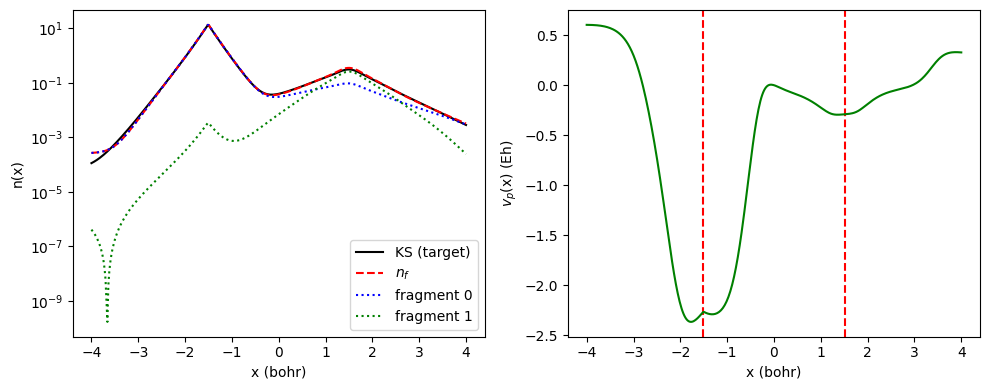

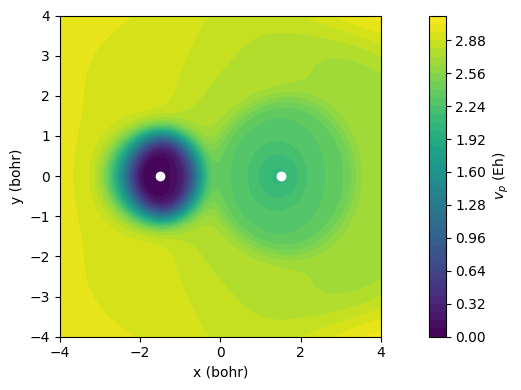

In [6]:
# # 1D plot along molecular axis
x = np.linspace(-4, 4, 400)
line = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
n_f = mf1.eval_density(line)                    # promolecular density
n_0 = mf1.eval_density(line, frag=0)            # fragment densities
n_1 = mf1.eval_density(line, frag=1)
vp  = mf1.eval_Vp(line)
n_ks = numint.eval_rho(mol.mol, numint.eval_ao(mol.mol, line), Dref) # target (plain KS) density on the same points
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(x, n_ks, 'k-', label='KS (target)')
ax[0].semilogy(x, n_f, 'r--', label='$n_f$')
ax[0].semilogy(x, n_0, 'b:', label='fragment 0')
ax[0].semilogy(x, n_1, 'g:', label='fragment 1')
for Ri in mol.mol.atom_coords(): ax[1].axvline(x=Ri[0], color='r', linestyle='dashed')
ax[0].set_xlabel('x (bohr)'); ax[0].set_ylabel('n(x)'); ax[0].legend()
ax[1].plot(x, vp - vp[len(x) // 2], 'g-')      # Vp is defined up to a constant: fix a reference point
ax[1].set_xlabel('x (bohr)'); ax[1].set_ylabel('$v_p$(x) (Eh)')
fig.tight_layout()
plt.show()

# 2D map of Vp in the xy plane (z = 0)
x = np.linspace(-4, 4, 160); yy = np.linspace(-4, 4, 160)
X, Y = np.meshgrid(x, yy)
pts = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])
V = mf1.eval_Vp(pts).reshape(X.shape)
fig, ax = plt.subplots(figsize=(10, 4))
c = ax.contourf(X, Y, V - V.min(), 40, cmap='viridis'); fig.colorbar(c, label='$v_p$ (Eh)')
for Ri in mol.mol.atom_coords():  ax.plot(Ri[0], Ri[1], 'wo')
ax.set_xlabel('x (bohr)'); ax.set_ylabel('y (bohr)'); ax.set_aspect('equal')
fig.tight_layout()
plt.show()